## Example

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path = r'D:\quant_learning\data\pandas_exercises\09_Time_Series\Apple_Stock\appl_1980_2014.csv'
a = pd.read_csv(path)
# a.info()
print(a['Date'].iloc[0],a['Date'].iloc[-1])

# a = pd.read_csv(path, parse_dates=['Date'])
a['Date'] = pd.to_datetime(a['Date'], format='%Y-%m-%d')
# a.info()

a = a.sort_values('Date').reset_index(drop=True)

a = a.set_index('Date')
a.head(10)

2014-07-08 1980-12-12


,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
1980-12-12,28.75,28.87,28.75,28.75,117258400,0.45
1980-12-15,27.38,27.38,27.25,27.25,43971200,0.42
1980-12-16,25.37,25.37,25.25,25.25,26432000,0.39
1980-12-17,25.87,26.00,25.87,25.87,21610400,0.40
1980-12-18,26.63,26.75,26.63,26.63,18362400,0.41
1980-12-19,28.25,28.38,28.25,28.25,12157600,0.44
1980-12-22,29.63,29.75,29.63,29.63,9340800,0.46
1980-12-23,30.88,31.00,30.88,30.88,11737600,0.48
1980-12-24,32.50,32.63,32.50,32.50,12000800,0.51


In [23]:
a2 = pd.read_csv(path,parse_dates=['Date'])
a2['Date'].dt.year
a2['Date'].dt.month
a2['Date'].dt.weekday
a2['Date'].dt.day_name()
a2['Date'].dt.quarter
a2['Date'].dt.is_month_end

a.index.year
a.index.month

Index([12, 12, 12, 12, 12, 12, 12, 12, 12, 12,
       ...
        6,  6,  6,  6,  6,  7,  7,  7,  7,  7],
      dtype='int32', name='Date', length=8465)

In [ ]:
a.loc['2010']
a.loc['2010-03']
a.loc['2012-06':'2013-06']
a.loc['2010-3-15']


Open         2.253800e+02
High         2.255000e+02
Low          2.202500e+02
Close        2.238400e+02
Volume       1.233757e+08
Adj Close    3.056000e+01
Name: 2010-03-15 00:00:00, dtype: float64

In [32]:
a['Close'].resample('W').mean()
a['Close'].resample('ME').mean()
a['Close'].resample('YE').mean()

Date
1980-12-31     30.443077
1981-12-31     24.311151
1982-12-31     19.142727
1983-12-31     37.521984
1984-12-31     26.801897
1985-12-31     20.194941
1986-12-31     32.460672
1987-12-31     53.889526
1988-12-31     41.538893
1989-12-31     41.658571
1990-12-31     37.561937
1991-12-31     52.494545
1992-12-31     54.802835
1993-12-31     41.026601
1994-12-31     34.080317
1995-12-31     40.540476
1996-12-31     24.919409
1997-12-31     17.966403
1998-12-31     30.564603
1999-12-31     57.770278
2000-12-31     71.749206
2001-12-31     20.219355
2002-12-31     19.139444
2003-12-31     18.544762
2004-12-31     35.526944
2005-12-31     52.401746
2006-12-31     70.810637
2007-12-31    128.273904
2008-12-31    141.979012
2009-12-31    146.814127
2010-12-31    259.842460
2011-12-31    364.004325
2012-12-31    576.049720
2013-12-31    472.634881
2014-12-31    478.036589
Freq: YE-DEC, Name: Close, dtype: float64

In [38]:
weekly = a.resample('W').agg(
    open=('Open','first'),
    high=('High','max'),
    low=('Low','min'),
    close=('Close','last'),
    volume=('Volume','sum')
).dropna()
weekly.info()

weekly2 = a.resample('W').agg({'Open':'first','High':'max','Low':'min','Close':'last','Volume':'sum'}).dropna()
weekly2.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1753 entries, 1980-12-14 to 2014-07-13
Freq: W-SUN
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    1753 non-null   float64
 1   high    1753 non-null   float64
 2   low     1753 non-null   float64
 3   close   1753 non-null   float64
 4   volume  1753 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 82.2 KB
<class 'pandas.DataFrame'>
DatetimeIndex: 1753 entries, 1980-12-14 to 2014-07-13
Freq: W-SUN
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    1753 non-null   float64
 1   High    1753 non-null   float64
 2   Low     1753 non-null   float64
 3   Close   1753 non-null   float64
 4   Volume  1753 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 82.2 KB


## Exercise

In [59]:
a = pd.read_csv(path,parse_dates=['Date'])
print(a['Date'].iloc[0],a['Date'].iloc[-1])
a = a.sort_values('Date',ignore_index=True)
a = a.set_index('Date')
print(a.shape)
print(a.index.min(),a.index.max())

2014-07-08 00:00:00 1980-12-12 00:00:00
(8465, 6)
1980-12-12 00:00:00 2014-07-08 00:00:00


In [72]:
a.loc['2010']
a.loc['2012-06':'2013-06']

a.index.year.value_counts()
a.index.year.value_counts()[2010]


np.int64(252)

In [ ]:
weekly_ex=a.resample('W').agg(
    open=('Open','first'),
    high=('High','max'),
    low=('Low','min'),
    close=('Close','last')
)
print((weekly_ex['high']>=weekly_ex['low']).value_counts())


True    1753
Name: count, dtype: int64


(404,)


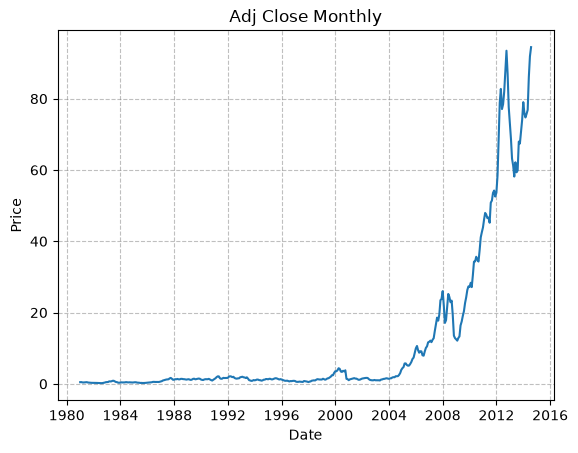

In [ ]:
adj_close_month = a['Adj Close'].resample('ME').mean()
print(adj_close_month.shape)
plt.plot(adj_close_month)
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Adj Close Monthly')
plt.grid(True,linestyle='--',alpha=0.5,color='gray')
plt.show()

(35,)


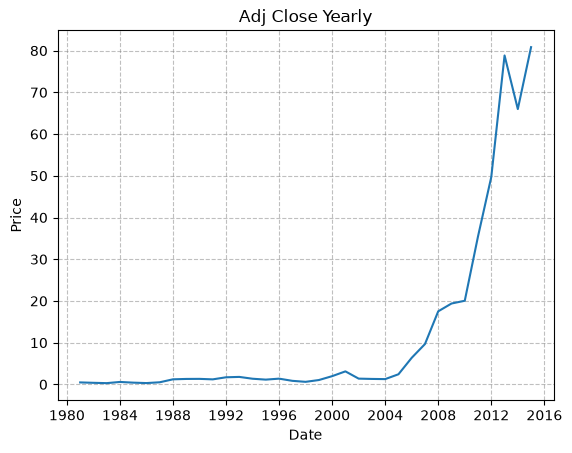

In [87]:
adj_close_year = a['Adj Close'].resample("YE").mean()
print(adj_close_year.shape)
plt.plot(adj_close_year)
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Adj Close Yearly')
plt.grid(True,linestyle='--',alpha=0.5,color='gray')
plt.show()

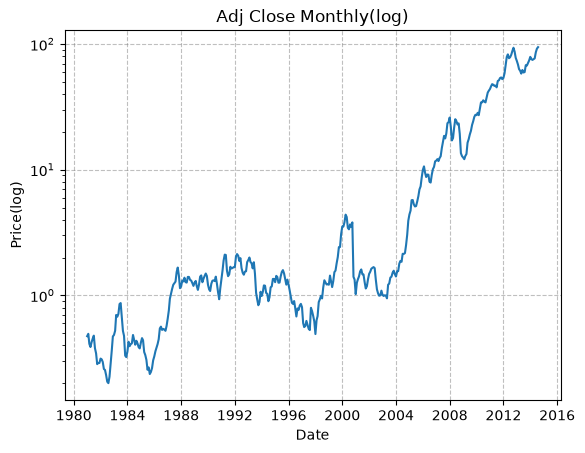

In [88]:

plt.plot(adj_close_month)
plt.yscale('log')
plt.xlabel('Date')
plt.ylabel('Price(log)')
plt.title('Adj Close Monthly(log)')
plt.grid(True,linestyle='--',alpha=0.5,color='gray')
plt.show()